**<h1 style='color:#DDA0DD'> Breast Cancer Prediction</h1>**


In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler


<h1 style="color:#D8BFD8;">Data Reading</h1>

In [11]:
df = pd.read_csv("/Users/saraa/Documents/Breast-Cancer-AI/data/data.csv")

In [12]:
df.head()

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


<h1 style='color:#DA70D6'>EDA</h1>

In [13]:
df.shape

(569, 33)

In [14]:
df.columns

Index(['id', 'diagnosis', 'radius_mean', 'texture_mean', 'perimeter_mean',
       'area_mean', 'smoothness_mean', 'compactness_mean', 'concavity_mean',
       'concave points_mean', 'symmetry_mean', 'fractal_dimension_mean',
       'radius_se', 'texture_se', 'perimeter_se', 'area_se', 'smoothness_se',
       'compactness_se', 'concavity_se', 'concave points_se', 'symmetry_se',
       'fractal_dimension_se', 'radius_worst', 'texture_worst',
       'perimeter_worst', 'area_worst', 'smoothness_worst',
       'compactness_worst', 'concavity_worst', 'concave points_worst',
       'symmetry_worst', 'fractal_dimension_worst', 'Unnamed: 32'],
      dtype='object')

In [15]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 33 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    object 
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    float64
 14  perimeter_se             5

In [16]:
df.describe()

,id,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
count,5.690000e+02,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,0.0
mean,3.037183e+07,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,...,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946,NaN
std,1.250206e+08,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,...,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061,NaN
min,8.670000e+03,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,...,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040,NaN
25%,8.692180e+05,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,...,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460,NaN
50%,9.060240e+05,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,...,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040,NaN
75%,8.813129e+06,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,...,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080,NaN
max,9.113205e+08,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,...,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500,NaN


In [17]:
df.isnull().sum()

id                           0
diagnosis                    0
radius_mean                  0
texture_mean                 0
perimeter_mean               0
area_mean                    0
smoothness_mean              0
compactness_mean             0
concavity_mean               0
concave points_mean          0
symmetry_mean                0
fractal_dimension_mean       0
radius_se                    0
texture_se                   0
perimeter_se                 0
area_se                      0
smoothness_se                0
compactness_se               0
concavity_se                 0
concave points_se            0
symmetry_se                  0
fractal_dimension_se         0
radius_worst                 0
texture_worst                0
perimeter_worst              0
area_worst                   0
smoothness_worst             0
compactness_worst            0
concavity_worst              0
concave points_worst         0
symmetry_worst               0
fractal_dimension_worst      0
Unnamed:

In [18]:
df["diagnosis"].value_counts()

diagnosis
B    357
M    212
Name: count, dtype: int64

**<h1 style='color:#9400D3'>Data Cleaning</h1>**

In [19]:
import pandas as pd
df = pd.read_csv("/Users/saraa/Documents/Breast-Cancer-AI/data/data.csv")

In [20]:
df.shape

(569, 33)

In [21]:
df=df.drop(columns=["Unnamed: 32"])

In [22]:
df.shape

(569, 32)

In [23]:
df.duplicated().sum()

0

In [24]:
df = df.drop_duplicates()

In [25]:
df = df.drop(columns=["id"])

In [26]:
df.shape

(569, 31)

In [27]:
df.dtypes

diagnosis                   object
radius_mean                float64
texture_mean               float64
perimeter_mean             float64
area_mean                  float64
smoothness_mean            float64
compactness_mean           float64
concavity_mean             float64
concave points_mean        float64
symmetry_mean              float64
fractal_dimension_mean     float64
radius_se                  float64
texture_se                 float64
perimeter_se               float64
area_se                    float64
smoothness_se              float64
compactness_se             float64
concavity_se               float64
concave points_se          float64
symmetry_se                float64
fractal_dimension_se       float64
radius_worst               float64
texture_worst              float64
perimeter_worst            float64
area_worst                 float64
smoothness_worst           float64
compactness_worst          float64
concavity_worst            float64
concave points_worst

In [28]:
df["diagnosis"].value_counts()

diagnosis
B    357
M    212
Name: count, dtype: int64

In [29]:
df["diagnosis"] = df["diagnosis"].map({"M": 1, "B": 0})

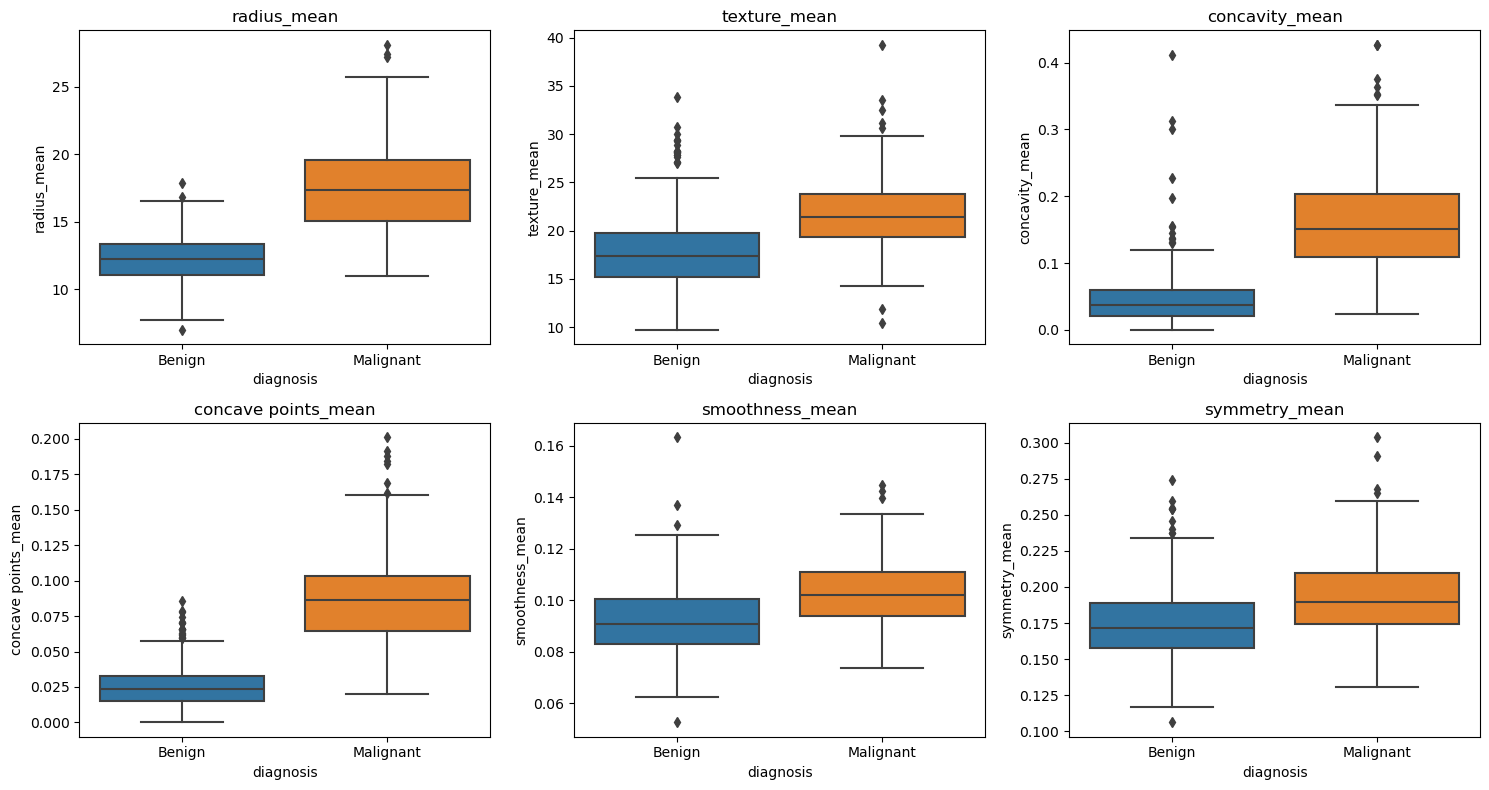

In [30]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
features_to_check = ['radius_mean', 'texture_mean', 'concavity_mean',
                      'concave points_mean', 'smoothness_mean', 'symmetry_mean']

for ax, feat in zip(axes.flat, features_to_check):
    sns.boxplot(data=df, x='diagnosis', y=feat, ax=ax)
    ax.set_title(feat)
    ax.set_xticklabels(['Benign', 'Malignant'])

plt.tight_layout()
plt.show()

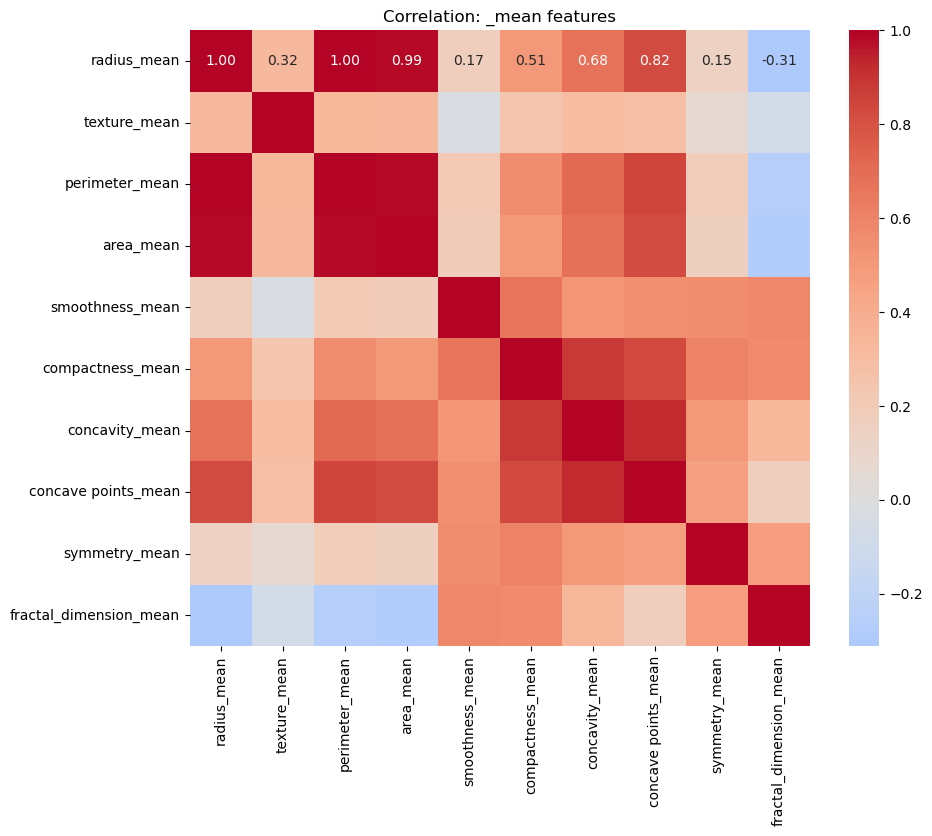

In [31]:
plt.figure(figsize=(10, 8))
mean_cols = [c for c in df.columns if c.endswith('_mean')]
sns.heatmap(df[mean_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation: _mean features')
plt.show()

In [32]:
df["diagnosis"].value_counts()

diagnosis
0    357
1    212
Name: count, dtype: int64

In [33]:
df.isnull().sum().sum()

0

In [34]:
x = df.drop(columns=["diagnosis"])
y = df["diagnosis"]

In [35]:
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42, stratify=y)

In [36]:
%pip install statsmodels

Note: you may need to restart the kernel to use updated packages.


In [37]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

vif_data = pd.DataFrame()
vif_data["feature"] = x_train.columns
vif_data["VIF"] = [variance_inflation_factor(x_train.values, i) for i in range(x_train.shape[1])]
vif_data = vif_data.sort_values("VIF", ascending=False)
vif_data

,feature,VIF
0,radius_mean,65941.888542
2,perimeter_mean,61423.042554
20,radius_worst,9481.381350
22,perimeter_worst,4572.688110
3,area_mean,1224.784552
23,area_worst,1079.060684
9,fractal_dimension_mean,662.882023
29,fractal_dimension_worst,464.958939
4,smoothness_mean,419.135118
24,smoothness_worst,388.596720


In [38]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
x_train_scaled = pd.DataFrame(scaler.fit_transform(x_train), columns=x_train.columns, index=x_train.index)
x_test_scaled = pd.DataFrame(scaler.transform(x_test), columns=x_test.columns, index=x_test.index)

<h1 style='color:#FFB6C1'>Model Training</h1>

<h2 style="color: #FFB6C1; font-size: 1.5em;">Supervised Learning</h2>

<h2 style="color: #E889A8; font-size: 1.5em;">Logistic Regression Model</h2>

<h3 style="color: #C2185B;">Model 1: Logistic Regression (Baseline)

### Why Logistic Regression first
Logistic Regression was chosen as the baseline model because it's simple, fast, and interpretable. it establishes a performance floor that any more complex model must justify beating. Reaching for a sophisticated model without first checking whether a simple linear model already performs well is
unjustified complexity, especially on a dataset this size (569 rows)</h3>

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import cross_val_score, cross_val_predict, StratifiedKFold
from sklearn.metrics import precision_recall_curve, classification_report, confusion_matrix

lr_model = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", LogisticRegression(C=1.0, max_iter=1000, random_state=42))
])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
recall_scores = cross_val_score(lr_model, x_train, y_train, cv=cv, scoring="recall")
print("CV recall:", recall_scores.round(3))
print("Mean CV recall:", recall_scores.mean())


oof_proba = cross_val_predict(
    lr_model, x_train, y_train, cv=cv, method="predict_proba"
)[:, 1]
precisions, recalls, thresholds = precision_recall_curve(y_train, oof_proba)
valid = np.where(recalls[:-1] >= 0.97)[0]
lr_threshold = thresholds[valid[-1]]
print("Logistic Regression threshold:", lr_threshold)

lr_model.fit(x_train, y_train)
y_proba_lr = lr_model.predict_proba(x_test)[:, 1]
y_pred_lr = (y_proba_lr >= lr_threshold).astype(int)

print("\nClassification report:")
print(classification_report(y_test, y_pred_lr, target_names=["Benign", "Malignant"]))
print("Confusion matrix:")
print(confusion_matrix(y_test, y_pred_lr))

CV recall: [0.882 0.971 1.    0.941 0.971]
Mean CV recall: 0.9529411764705882
Logistic Regression threshold: 0.3142903652549661

Classification report:
              precision    recall  f1-score   support

      Benign       0.99      0.99      0.99        72
   Malignant       0.98      0.98      0.98        42

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114

Confusion matrix:
[[71  1]
 [ 1 41]]


In [41]:
from sklearn.metrics import precision_recall_curve
from sklearn.model_selection import cross_val_predict, cross_val_score, StratifiedKFold
from sklearn.linear_model import LogisticRegression

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
import pandas as pd

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
model = Pipeline([
    ('scaler', StandardScaler()),
    ('logistic_regression', LogisticRegression(
        penalty='l2',
        C=1.0,
        random_state=42,
        max_iter=1000
    ))
])

if "x_train" not in globals() or "x_test" not in globals():
    if "df" not in globals():
        df = pd.read_csv("/Users/saraa/Documents/Breast-Cancer-AI/data/data.csv")
    x = df.drop(columns=["diagnosis"])
    y = df["diagnosis"]
    x_train, x_test, y_train, y_test = train_test_split(
        x, y, test_size=0.2, random_state=42, stratify=y
    )

oof_proba = cross_val_predict(
    model, x_train, y_train,
    cv=cv,
    method="predict_proba"
)[:, 1]

p, r, t = precision_recall_curve(y_train, oof_proba)
valid = np.where(r[:-1] >= 0.97)[0]
chosen_threshold = t[valid[-1]]
print("Threshold:", chosen_threshold)

model.fit(x_train, y_train)
y_pred_final = (model.predict_proba(x_test)[:, 1] >= chosen_threshold).astype(int)
print(classification_report(y_test, y_pred_final, target_names=['Benign', 'Malignant']))
print(confusion_matrix(y_test, y_pred_final))

Threshold: 0.3142903652549661
              precision    recall  f1-score   support

      Benign       0.99      0.99      0.99        72
   Malignant       0.98      0.98      0.98        42

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114

[[71  1]
 [ 1 41]]


In [50]:
target_recall = 0.95
valid_idx = np.where(recalls[:-1] >= target_recall)[0]

if len(valid_idx) == 0:
    raise ValueError(f"No threshold achieves recall >= {target_recall:.2f}")

idx = valid_idx[-1]
custom_threshold = thresholds[idx]

lr_model.fit(x_train, y_train)
y_proba_lr = lr_model.predict_proba(x_test)[:, 1]
y_pred_custom = (y_proba_lr >= custom_threshold).astype(int)

print(classification_report(y_test, y_pred_custom, target_names=["Benign", "Malignant"]))
print(confusion_matrix(y_test, y_pred_custom))

              precision    recall  f1-score   support

      Benign       0.96      1.00      0.98        72
   Malignant       1.00      0.93      0.96        42

    accuracy                           0.97       114
   macro avg       0.98      0.96      0.97       114
weighted avg       0.97      0.97      0.97       114

[[72  0]
 [ 3 39]]


In [51]:
for target_recall in [0.90, 0.93, 0.95, 0.97, 0.98, 1.00]:
    valid_idx = np.where(recalls[:-1] >= target_recall)[0]
    idx = valid_idx[-1]
    print(f"Target recall {target_recall:.2f} → Threshold: {thresholds[idx]:.3f}, "
          f"Precision: {precisions[idx]:.3f}, Recall: {recalls[idx]:.3f}")

Target recall 0.90 → Threshold: 0.894, Precision: 1.000, Recall: 0.900
Target recall 0.93 → Threshold: 0.664, Precision: 1.000, Recall: 0.935
Target recall 0.95 → Threshold: 0.511, Precision: 0.976, Recall: 0.953
Target recall 0.97 → Threshold: 0.314, Precision: 0.954, Recall: 0.971
Target recall 0.98 → Threshold: 0.207, Precision: 0.928, Recall: 0.982
Target recall 1.00 → Threshold: 0.003, Precision: 0.557, Recall: 1.000


In [52]:
target_recall = 0.95
valid_idx = np.where(recalls[:-1] >= target_recall)[0]

if len(valid_idx) == 0:
    raise ValueError(f"No threshold achieves recall >= {target_recall:.2f}")

idx = valid_idx[-1]
custom_threshold = thresholds[idx]

y_pred_custom = (y_proba_lr >= custom_threshold).astype(int)
print(classification_report(y_test, y_pred_custom, target_names=["Benign", "Malignant"]))
print(confusion_matrix(y_test, y_pred_custom))

              precision    recall  f1-score   support

      Benign       0.96      1.00      0.98        72
   Malignant       1.00      0.93      0.96        42

    accuracy                           0.97       114
   macro avg       0.98      0.96      0.97       114
weighted avg       0.97      0.97      0.97       114

[[72  0]
 [ 3 39]]


<h2 style="color: #D96C91; font-size: 1.5em;">Random Forest Classifier</h2>

In [53]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(x_train, y_train)  

y_pred_rf = rf_model.predict(x_test)
y_proba_rf = rf_model.predict_proba(x_test)[:, 1]

print(classification_report(y_test, y_pred_rf, target_names=['Benign', 'Malignant']))
print(confusion_matrix(y_test, y_pred_rf))
print("ROC-AUC:", roc_auc_score(y_test, y_proba_rf))

# Cross-validation
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
rf_recall_scores = cross_val_score(rf_model, x_train, y_train, cv=cv, scoring='recall')
print("RF Recall per fold:", rf_recall_scores)
print("RF Mean recall:", rf_recall_scores.mean(), "Std:", rf_recall_scores.std())

              precision    recall  f1-score   support

      Benign       0.96      1.00      0.98        72
   Malignant       1.00      0.93      0.96        42

    accuracy                           0.97       114
   macro avg       0.98      0.96      0.97       114
weighted avg       0.97      0.97      0.97       114

[[72  0]
 [ 3 39]]
ROC-AUC: 0.9928902116402116
RF Recall per fold: [0.91176471 1.         0.88235294 0.97058824 0.94117647]
RF Mean recall: 0.9411764705882353 Std: 0.04159451654038516


                 feature  importance
23            area_worst    0.151412
27  concave points_worst    0.126497
20          radius_worst    0.093475
22       perimeter_worst    0.083642
7    concave points_mean    0.081082
2         perimeter_mean    0.077126
0            radius_mean    0.061990
6         concavity_mean    0.050818
3              area_mean    0.045916
26       concavity_worst    0.030022


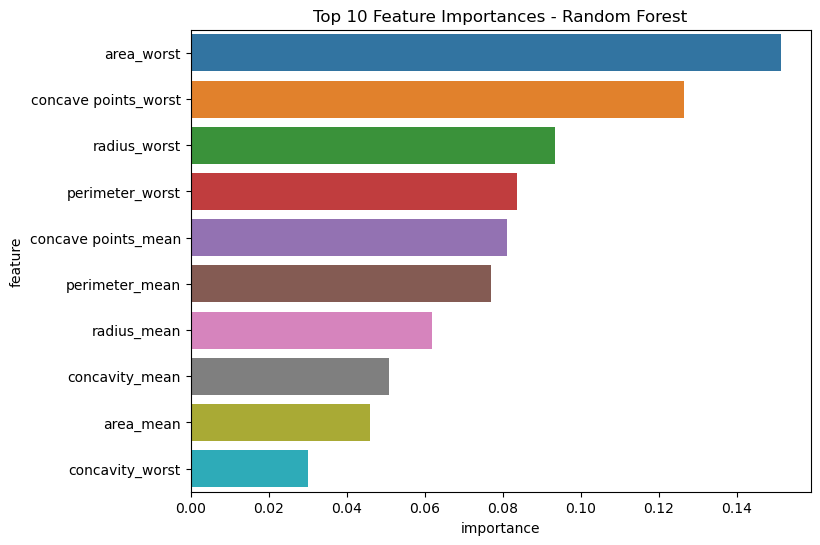

In [54]:
importances = pd.DataFrame({
    'feature': x_train.columns,
    'importance': rf_model.feature_importances_
}).sort_values('importance', ascending=False)

print(importances.head(10))

plt.figure(figsize=(8, 6))
sns.barplot(data=importances.head(10), x='importance', y='feature')
plt.title('Top 10 Feature Importances - Random Forest')
plt.show()

In [55]:
precisions_rf, recalls_rf, thresholds_rf = precision_recall_curve(y_test, y_proba_rf)

for target_recall in [0.90, 0.93, 0.95, 0.97, 0.98, 1.00]:
    valid_idx = np.where(recalls_rf[:-1] >= target_recall)[0]
    if len(valid_idx) > 0:
        idx = valid_idx[-1]
        print(f"Target recall {target_recall:.2f} → Threshold: {thresholds_rf[idx]:.3f}, "
              f"Precision: {precisions_rf[idx]:.3f}, Recall: {recalls_rf[idx]:.3f}")

Target recall 0.90 → Threshold: 0.590, Precision: 1.000, Recall: 0.905
Target recall 0.93 → Threshold: 0.270, Precision: 0.930, Recall: 0.952
Target recall 0.95 → Threshold: 0.270, Precision: 0.930, Recall: 0.952
Target recall 0.97 → Threshold: 0.190, Precision: 0.872, Recall: 0.976
Target recall 0.98 → Threshold: 0.100, Precision: 0.750, Recall: 1.000
Target recall 1.00 → Threshold: 0.100, Precision: 0.750, Recall: 1.000


<h2 style="color: #FF69B4; font-size: 2em;">Unsupervised Learning (PCA + K-Means)</h2>

Explained variance: [0.446 0.185 0.096 0.066 0.056 0.04  0.022 0.016 0.013 0.012]
Cumulative: [0.446 0.631 0.727 0.793 0.849 0.889 0.911 0.928 0.94  0.952]


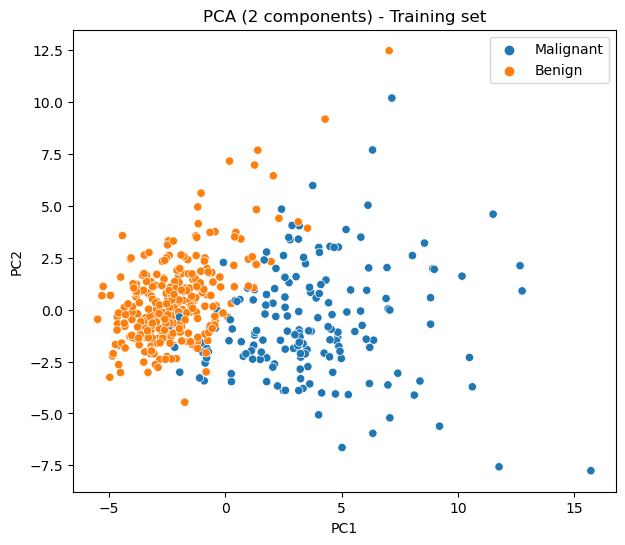

Adjusted Rand Index: 0.662
[[ 15 270]
 [143  27]]


In [56]:
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score

scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)

# PCA
pca = PCA(n_components=10, random_state=42)
x_pca = pca.fit_transform(x_train_scaled)
print("Explained variance:", pca.explained_variance_ratio_.round(3))
print("Cumulative:", pca.explained_variance_ratio_.cumsum().round(3))

plt.figure(figsize=(7, 6))
sns.scatterplot(x=x_pca[:, 0], y=x_pca[:, 1],
                hue=y_train.map({0: "Benign", 1: "Malignant"}).values)
plt.xlabel("PC1"); plt.ylabel("PC2")
plt.title("PCA (2 components) - Training set")
plt.show()


kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)
clusters = kmeans.fit_predict(x_train_scaled)
print("Adjusted Rand Index:", round(adjusted_rand_score(y_train, clusters), 3))
print(confusion_matrix(y_train, clusters))

<h2 style="color: #C2185B; font-size: 2em;">Deep Learning (Neural Network)</h2>

In [ ]:
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, roc_auc_score


def pick_threshold(model, X, y, target_recall=0.95):
    oof_proba = cross_val_predict(model, X, y, cv=cv, method="predict_proba")[:, 1]
    precisions, recalls, thresholds = precision_recall_curve(y, oof_proba)
    valid = np.flatnonzero(recalls[:-1] >= target_recall)

    if len(valid) == 0:
        raise ValueError(f"No threshold achieves recall >= {target_recall:.2f}")

    return thresholds[valid[-1]]


def evaluate(model, X, y, threshold, model_name):
    y_proba = model.predict_proba(X)[:, 1]
    y_pred = (y_proba >= threshold).astype(int)

    print(f"\n{model_name} Results")
    print(classification_report(y, y_pred, target_names=["Benign", "Malignant"]))
    print("Confusion matrix:")
    print(confusion_matrix(y, y_pred))

    return {
        "Model": model_name,
        "Accuracy": accuracy_score(y, y_pred),
        "Precision": precision_score(y, y_pred),
        "Recall": recall_score(y, y_pred),
        "ROC-AUC": roc_auc_score(y, y_proba),
    }


mlp_model = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", MLPClassifier(hidden_layer_sizes=(32, 16), activation="relu",
                          alpha=1e-3, early_stopping=True, validation_fraction=0.15,
                          max_iter=500, random_state=42))
])

print("CV recall:", cross_val_score(mlp_model, x_train, y_train, cv=cv, scoring="recall").round(3))

mlp_threshold = pick_threshold(mlp_model, x_train, y_train, target_recall=0.95)
mlp_model.fit(x_train, y_train)

mlp_result = evaluate(mlp_model, x_test, y_test, mlp_threshold, "Neural Network")

# Compare the final test results for all models.
lr_y_pred = (y_proba_lr >= lr_threshold).astype(int)
comparison_results = [
    {
        "Model": "Logistic Regression",
        "Accuracy": accuracy_score(y_test, y_pred_lr),
        "Precision": precision_score(y_test, y_pred_lr),
        "Recall": recall_score(y_test, y_pred_lr),
        "ROC-AUC": roc_auc_score(y_test, y_proba_lr),
    },
    {
        "Model": "Random Forest",
        "Accuracy": accuracy_score(y_test, y_pred_rf),
        "Precision": precision_score(y_test, y_pred_rf),
        "Recall": recall_score(y_test, y_pred_rf),
        "ROC-AUC": roc_auc_score(y_test, y_proba_rf),
    },
    mlp_result,
]

model_comparison = pd.DataFrame(comparison_results).set_index("Model")
print("\nFinal Model Comparison:")
print(model_comparison.round(3))

CV recall: [0.794 0.882 0.735 0.559 0.882]
              precision    recall  f1-score   support

      Benign       1.00      0.64      0.78        72
   Malignant       0.62      1.00      0.76        42

    accuracy                           0.77       114
   macro avg       0.81      0.82      0.77       114
weighted avg       0.86      0.77      0.77       114

[[46 26]
 [ 0 42]]
